# 08 · 最新人工眨眼标注与全部检测汇总

读取本轮更新后的全部人工CSV/FIF，并对已有检测结果作对照。原固定8文件pilot保持不变；对有人工标注、但不在固定pilot内的训练EDF，使用**完全相同的参数**补充检测，另存在 `outputs/blink_annotation_update/additional_edfs`。

这些补充文件由人工标注可用性选择，不能当作随机抽样或独立盲测。本轮不调任何阈值，不删除epoch，也不把候选当作已确认眨眼。旧05/06/07中的人工对照属于当时快照，本notebook是当前汇总入口。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
OUT=ROOT/'outputs/blink_annotation_update'
summary=pd.read_csv(OUT/'annotation_update_summary.csv')
all_files=pd.read_csv(OUT/'all_processed_detection_summary.csv')
detail=pd.read_csv(OUT/'manual_candidate_details.csv')
pairs=pd.read_csv(OUT/'manual_candidate_pairs.csv')
record=json.loads((OUT/'analysis_record.json').read_text())
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(record,name='current snapshot').to_frame())

,current snapshot
annotated_files,6
manual_spans,203
nonstartup_manual_spans,183
nonstartup_manual_spans_with_overlap,181
nonstartup_manual_spans_without_overlap,2
total_processed_files,12
all_processed_blink_candidates,595
all_processed_flashes,9054
config_unchanged,True
frozen_manifest_unchanged,True


## 1. 六份已保存标注逐文件汇总

每份CSV与FIF时间/标签一致性均检查。`MANUAL_bad_span`按用户说明视为疑似眨眼时间段，不是永久坏通道。人工标注与检测候选可以多对多相交。

下表同时给出全部人工段数、启动期段数、非启动期段数和与非启动期候选相交的段数。相交只需有正时长重叠；这不是严格边界吻合，也不是正式召回率。

,edf_name,in_frozen_pilot,suspected_manual_spans,startup_spans,nonstartup_spans,nonstartup_spans_with_overlap,nonstartup_spans_without_overlap,auto_candidates,source_consistency
0,F_05_SE001_CBCol_Train02.edf,True,51,3,48,47,1,95,CSV_FIF_agree
1,F_05_SE002_CBCol_Train01.edf,True,39,3,36,35,1,102,CSV_FIF_agree
2,F_05_SE002_CBCol_Train02.edf,False,26,3,23,23,0,126,CSV_FIF_agree
3,F_05_SE003_CBCol_Train04.edf,False,60,6,54,54,0,140,CSV_FIF_agree
4,F_08_SE003_CBCol_Train03.edf,False,24,3,21,21,0,33,CSV_FIF_agree
5,F_25_SE001_CBCol_Train01.edf,False,3,2,1,1,0,70,CSV_FIF_agree


非启动期已标段与候选重叠： 181 / 183


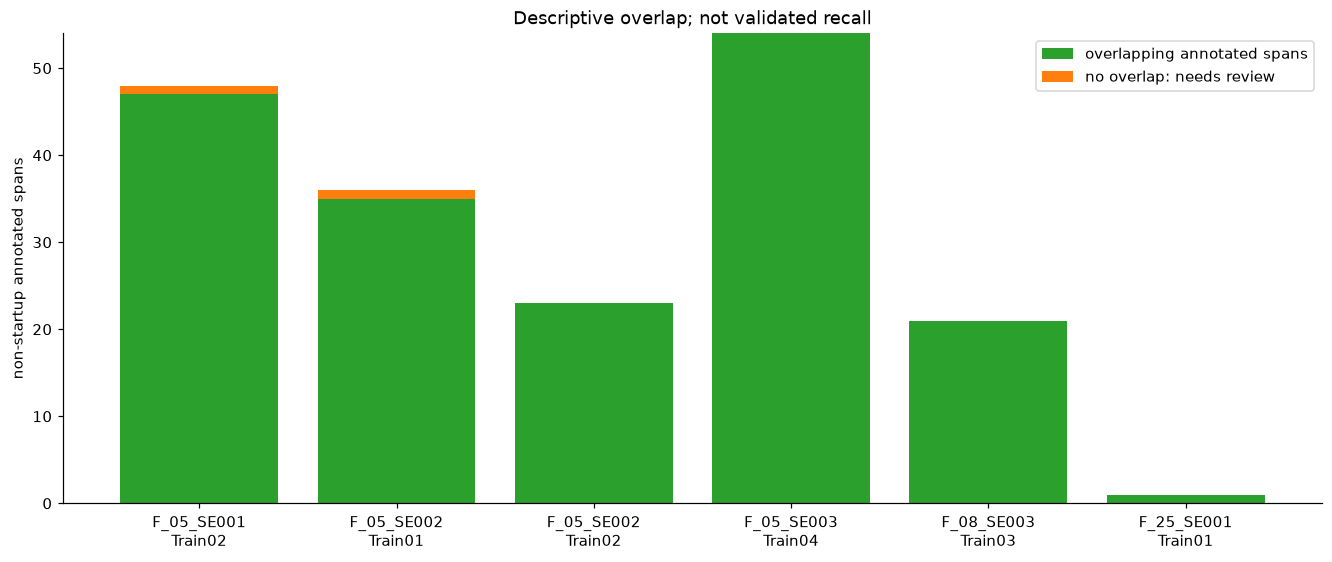

In [2]:
cols=['edf_name','in_frozen_pilot','suspected_manual_spans','startup_spans','nonstartup_spans',
      'nonstartup_spans_with_overlap','nonstartup_spans_without_overlap','auto_candidates','source_consistency']
display(summary[cols])
print('非启动期已标段与候选重叠：',summary.nonstartup_spans_with_overlap.sum(),'/',summary.nonstartup_spans.sum())
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
x=np.arange(len(summary));matched=summary.nonstartup_spans_with_overlap
ax.bar(x,matched,label='overlapping annotated spans',color='tab:green')
ax.bar(x,summary.nonstartup_spans_without_overlap,bottom=matched,label='no overlap: needs review',color='tab:orange')
ax.set(xticks=x,xticklabels=[f'{r.edf_name.split("_CBCol")[0]}\n{r.edf_name.split("_CBCol_")[1].removesuffix(".edf")}' for r in summary.itertuples()],ylabel='non-startup annotated spans',title='Descriptive overlap; not validated recall')
ax.legend();plt.show()

## 2. 尚未与候选重叠的人工片段

下面列出所有非启动期的未相交标注。它们值得逐段复核，但在稀疏、疑似眨眼标注条件下，不能直接宣布为确定漏检。辅助因果分支会改变波形时序，狭窄的人工区间也可能与候选边界错开。

max_overlapping_epoch_ptp_uv是与人工区间相交的epoch里、全通道最大PTP，不是眨眼波形自身幅值，不能直接用于重设眨眼检测门槛。

In [3]:
unmatched=pd.read_csv(OUT/'unmatched_nonstartup_manual.csv')
display(unmatched[['edf_name','manual_id','start_sec','end_sec','overlap_epochs','max_overlapping_epoch_ptp_uv']])
print('未重叠详细记录：',OUT/'unmatched_nonstartup_manual.csv')

,edf_name,manual_id,start_sec,end_sec,overlap_epochs,max_overlapping_epoch_ptp_uv
0,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0031,89.500282,89.636914,4,106.573122
1,F_05_SE002_CBCol_Train01.edf,F_05_SE002_CBCol_Train01_M0021,55.614507,56.062850,5,194.055737


未重叠详细记录： D:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_annotation_update\unmatched_nonstartup_manual.csv


## 3. 人工区间覆盖程度与边界差

某候选与人工区间只相交一点也会计为“有重叠”，因此补看人工区间有多少时长被候选覆盖，以及相交对的起止差。注意人工标注在原始信号域，候选在额外因果低通分支上，边界差混合了滤波相位和人工边界误差，不是已验证定位精度。

同一个候选可能跨多个人工标注，同一人工标注也可能与多个候选相交；下表按配对描述，不能把配对数当作独立事件数。

,count,min,median,mean,max
edf_name,,,,,
F_05_SE001_CBCol_Train02.edf,48,0.000000,0.552284,0.547569,1.000000
F_05_SE002_CBCol_Train01.edf,36,0.000000,0.598397,0.600877,1.000000
F_05_SE002_CBCol_Train02.edf,23,0.455338,0.656825,0.661657,1.000000
F_05_SE003_CBCol_Train04.edf,54,0.399753,0.680515,0.671671,1.000000
F_08_SE003_CBCol_Train03.edf,21,0.574652,0.714243,0.762975,1.000000
F_25_SE001_CBCol_Train01.edf,1,0.653655,0.653655,0.653655,0.653655


overlap_seconds                                \
                                       count    median       min       max   
edf_name                                                                     
F_05_SE001_CBCol_Train02.edf              50  0.162111  0.026011  0.344879   
F_05_SE002_CBCol_Train01.edf              38  0.181518  0.040374  0.287180   
F_05_SE002_CBCol_Train02.edf              25  0.197458  0.123549  0.349318   
F_05_SE003_CBCol_Train04.edf              60  0.218645  0.111191  0.428980   
F_08_SE003_CBCol_Train03.edf              22  0.248263  0.170790  0.414598   
F_25_SE001_CBCol_Train01.edf               2  0.124318  0.099850  0.148785   

                             onset_difference_seconds                      \
                                                count    median       min   
edf_name                                                                    
F_05_SE001_CBCol_Train02.edf                       50  0.135684 -0.271070   
F_05_SE002_CBCol_Train01.edf                       38  0.120361 -0.198774   
F_05_SE002_CBCol_Train02.edf                       25  0.099025 -0.597298   
F_05_SE003_CBCol_Train04.edf                       60  0.110057 -0.352522   
F_08_SE003_CBCol_Train03.edf                       22  0.086651 -0.357947   
F_25_SE001_CBCol_Train01.edf                        2  0.141239  0.078835   

                                       offset_difference_seconds            \
                                   max                     count    median   
edf_name                                                                     
F_05_SE001_CBCol_Train02.edf  0.295075                        50  0.197825   
F_05_SE002_CBCol_Train01.edf  0.211746                        38  0.257117   
F_05_SE002_CBCol_Train02.edf  0.184086                        25  0.244277   
F_05_SE003_CBCol_Train04.edf  0.326258                        60  0.209405   
F_08_SE003_CBCol_Train03.edf  0.212623                        22  0.261644   
F_25_SE001_CBCol_Train01.edf  0.203644                         2  0.436229   

                                                  
                                   min       max  
edf_name                                          
F_05_SE001_CBCol_Train02.edf -0.093109  0.746975  
F_05_SE002_CBCol_Train01.edf  0.103445  0.887907  
F_05_SE002_CBCol_Train02.edf  0.146636  0.950576  
F_05_SE003_CBCol_Train04.edf -0.029173  0.896552  
F_08_SE003_CBCol_Train03.edf  0.085635  0.909752  
F_25_SE001_CBCol_Train01.edf  0.208744  0.663715

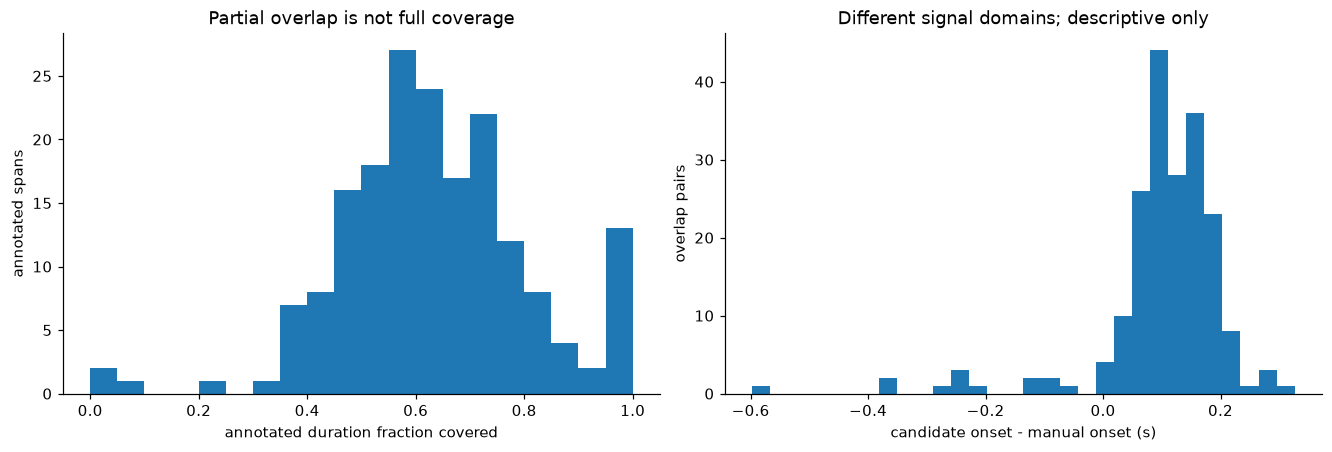

In [4]:
d=detail[~detail.startup]
display(d.groupby('edf_name').manual_duration_covered_fraction.agg(['count','min','median','mean','max']))
display(pairs.groupby('edf_name')[['overlap_seconds','onset_difference_seconds','offset_difference_seconds']].agg(['count','median','min','max']))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].hist(d.manual_duration_covered_fraction,bins=np.linspace(0,1,21))
axes[0].set(xlabel='annotated duration fraction covered',ylabel='annotated spans',title='Partial overlap is not full coverage')
axes[1].hist(pairs.onset_difference_seconds,bins=30)
axes[1].set(xlabel='candidate onset - manual onset (s)',ylabel='overlap pairs',title='Different signal domains; descriptive only')
plt.show()

## 4. 所有已处理文件：固定pilot与补充文件分开

这张表覆盖原8份文件和本次4份补充训练文件，不重复计算已在pilot内的已标注文件。manually_annotated=False表示没有找到当前人工标注，并不表示正常。没有候选也不代表该文件无眨眼。

仅汇总候选数、关联epoch数、启动epoch与基础跳变。站点全部仍为inferred，未按候选结果改动原固定文件清单。

In [5]:
display(all_files[['edf_name','site','in_frozen_pilot','manually_annotated','flashes','auto_candidates',
                   'nonstartup_auto_candidates','epochs_with_candidate','filter_startup_epochs','jump_candidates','other_basic_candidates']])
for name,g in all_files.groupby('in_frozen_pilot'):
    print('原固定pilot' if name else '人工标注补充文件',':',len(g),'files;',g.flashes.sum(),'flashes;',g.auto_candidates.sum(),'candidates')

,edf_name,site,in_frozen_pilot,manually_annotated,flashes,auto_candidates,nonstartup_auto_candidates,epochs_with_candidate,filter_startup_epochs,jump_candidates,other_basic_candidates
0,F_03_SE001_CBCol_Train01.edf,ETSU,True,False,756,3,2,0,22,0,0
1,F_03_SE002_CBCol_Train01.edf,ETSU,True,False,756,6,3,12,22,0,0
2,F_05_SE001_CBCol_Train02.edf,Duke,True,True,756,95,91,333,22,15,0
3,F_05_SE002_CBCol_Train01.edf,Duke,True,True,756,102,97,418,22,117,0
4,F_06_SE001_CBCol_Train01.edf,Duke,True,False,756,2,2,0,22,0,0
5,F_06_SE002_CBCol_Train01.edf,Duke,True,False,756,0,0,0,22,27,0
6,F_20_SE001_CBCol_Train01.edf,ETSU,True,False,756,6,6,4,22,0,0
7,F_20_SE002_CBCol_Train01.edf,ETSU,True,False,738,12,11,18,22,0,0
8,F_05_SE002_CBCol_Train02.edf,Duke,False,True,756,126,123,509,22,38,0
9,F_05_SE003_CBCol_Train04.edf,Duke,False,True,756,140,133,509,22,9,0


人工标注补充文件 : 4 files; 3024 flashes; 369 candidates
原固定pilot : 8 files; 6030 flashes; 226 candidates


## 5. 自动候选没有人工重叠，如何解释？

下表给出已标注文件内的自动候选数，以及没有与任何已保存标注相交的数量。这些候选可能是未标出的眨眼，也可能是其他额区变化；**不能称为误报，不能算精确率**。同样，人工有重叠的候选也只是疑似匹配，不是确诊眼动来源。

要评价漏检和误报，需要完整检查的连续区间及明确不确定片段。当前reviewed_intervals仍缺少，程序没有生成ground truth。

In [6]:
display(summary[['edf_name','nonstartup_auto_candidates','nonstartup_auto_candidates_overlapping_manual',
                 'auto_candidates_without_manual_overlap','complete_reviewed_intervals','reviewed_event_recall','reviewed_candidate_match_fraction']])
print('注意auto_candidates_without_manual_overlap包含启动期候选；其他两列明确仅非启动期。')

,edf_name,nonstartup_auto_candidates,nonstartup_auto_candidates_overlapping_manual,auto_candidates_without_manual_overlap,complete_reviewed_intervals,reviewed_event_recall,reviewed_candidate_match_fraction
0,F_05_SE001_CBCol_Train02.edf,91,46,46,0,NaN,NaN
1,F_05_SE002_CBCol_Train01.edf,97,35,64,0,NaN,NaN
2,F_05_SE002_CBCol_Train02.edf,123,23,101,0,NaN,NaN
3,F_05_SE003_CBCol_Train04.edf,133,53,81,1,1.0,0.8
4,F_08_SE003_CBCol_Train03.edf,31,21,11,1,1.0,1.0
5,F_25_SE001_CBCol_Train01.edf,65,1,68,0,NaN,NaN


注意auto_candidates_without_manual_overlap包含启动期候选；其他两列明确仅非启动期。


## 6. PTP方案模拟与眨眼候选分开

下表仍只模拟150/250µV上限与无上限方案的预计有效epoch数。基础条件相同；眨眼候选不参与拒绝。no_upper也仍保留启动、不完整、非有限、恢复、原始平线与过低PTP等条件。

新增标注只帮助检查检测器，不意味着需要调PTP上限。PTP不是眨眼来源特异指标，不能因希望覆盖所有眨眼而直接降低到大量拒绝的数值。

In [7]:
display(all_files[['edf_name','flashes','all16_upper_150uv_expected_kept','all16_upper_250uv_expected_kept','all16_no_upper_expected_kept']])
params=json.loads((ROOT/'configs/expanded_pilot.json').read_text())
display(pd.Series(params['blink_detector'],name='unchanged candidate parameter').to_frame())

,edf_name,flashes,all16_upper_150uv_expected_kept,all16_upper_250uv_expected_kept,all16_no_upper_expected_kept
0,F_03_SE001_CBCol_Train01.edf,756,734,734,734
1,F_03_SE002_CBCol_Train01.edf,756,734,734,734
2,F_05_SE001_CBCol_Train02.edf,756,729,734,734
3,F_05_SE002_CBCol_Train01.edf,756,629,734,734
4,F_06_SE001_CBCol_Train01.edf,756,725,734,734
5,F_06_SE002_CBCol_Train01.edf,756,734,734,734
6,F_20_SE001_CBCol_Train01.edf,756,734,734,734
7,F_20_SE002_CBCol_Train01.edf,738,716,716,716
8,F_05_SE002_CBCol_Train02.edf,756,501,734,734
9,F_05_SE003_CBCol_Train04.edf,756,731,734,734


,unchanged candidate parameter
status,unvalidated engineering candidates; fixed para...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"
posterior_channels,"[EEG_Pz, EEG_PO7, EEG_PO8, EEG_Oz]"
auxiliary_lowpass_hz,5.0
auxiliary_order,2
entry_uv,20.0
exit_uv,10.0
min_frontal_amplitude_uv,25.0
min_support_channels,2
support_peak_fraction,0.5


## 7. 当前结论与一致性检查

当前不自动调整阈值。先看新增文件是否重复出现特定的未匹配波形或边界模式，再用完整检查的区间评估降低门槛的代价。已标正例的高重叠比例本身不足以确定参数最优。

同一F_05多个Session并非多个独立被试；六份标注集中在少数被试，跨被试泛化证据仍有限。补充文件因有人工标注而被选入，也不是独立盲测。

重复运行：`D:/Anaconda/envs/bigp3bci/python.exe scripts/check_blink_annotation_updates.py`。检测参数和原固定8文件manifest的hash在处理前后保持一致；旧检测结果可复用，新增文件的原始EDF处理前后hash同样保存。下列检查只验证产物一致性，不证明检测有效。

In [8]:
assert summary.source_consistency.eq('CSV_FIF_agree').all()
assert summary.suspected_manual_spans.sum()==len(detail)
assert summary.nonstartup_spans.sum()==detail.startup.eq(False).sum()
assert summary.nonstartup_spans_with_overlap.sum()==((~detail.startup)&detail.has_nonstartup_candidate_overlap).sum()
assert len(all_files)==all_files.edf_name.nunique()
assert record['config_unchanged'] and record['frozen_manifest_unchanged']
unreviewed=summary.complete_reviewed_intervals.eq(0)
assert summary.loc[unreviewed,'reviewed_event_recall'].isna().all()
assert summary.loc[unreviewed,'reviewed_candidate_match_fraction'].isna().all()
print('PASS: annotation sources, counts, unique files, unchanged parameters and unavailable validation metrics')

PASS: annotation sources, counts, unique files, unchanged parameters and unavailable validation metrics


## 8. ????F_08 SE003 Train03?????1?50?

???????????10?50???4??????4???????????????????????????????????????

49.844?50.852???????????????????51.004?????????????????????????49.720?50.055?????

1?10???????1.527?2.000???????????2.316?2.630??3.395?3.826????????????????????????????

??????????????????????????????????????

In [9]:
f08=OUT/'per_edf/F_08_SE003_CBCol_Train03'
display(pd.Series(json.loads((f08/'manual_validation_status.json').read_text()),name='reviewed F08 status').to_frame())
c=pd.read_csv(f08/'manual_candidate_comparison.csv')
display(c.loc[c.onset_seconds<51,['blink_candidate_id','onset_seconds','offset_seconds','decision_seconds','filter_startup','fully_reviewed','evaluation_status']])
m=pd.read_csv(f08/'manual_event_comparison.csv')
display(m.loc[m.start_sec<51,['manual_id','start_sec','end_sec','matching_candidate_ids','evaluation_status']])
assert c.loc[c.evaluation_eligible,'evaluation_status'].eq('matched').all()

,reviewed F08 status
edf_name,F_08_SE003_CBCol_Train03.edf
manual_sources,"[""outputs\\artifact_qc\\continuous_manual_qc\\..."
manual_source_consistency,agree
suspected_manual_blinks,24
complete_reviewed_intervals,1
reviewed_seconds,49.0
evaluated_manual_events,4
evaluated_candidates,4
matched_manual_events,4
unmatched_candidates,0


,blink_candidate_id,onset_seconds,offset_seconds,decision_seconds,filter_startup,fully_reviewed,evaluation_status
0,F_08_SE003_CBCol_Train03_B0001,0.878906,1.363281,1.515625,True,False,unreviewed_or_boundary_or_startup
1,F_08_SE003_CBCol_Train03_B0002,1.527344,2.000000,2.152344,True,True,unreviewed_or_boundary_or_startup
2,F_08_SE003_CBCol_Train03_B0003,16.710938,17.699219,17.851562,False,True,matched
3,F_08_SE003_CBCol_Train03_B0004,26.457031,26.902344,27.054688,False,True,matched
4,F_08_SE003_CBCol_Train03_B0005,35.949219,36.953125,37.105469,False,True,matched
5,F_08_SE003_CBCol_Train03_B0006,38.117188,38.925781,39.078125,False,True,matched
6,F_08_SE003_CBCol_Train03_B0007,49.843750,50.851562,51.003906,False,False,unreviewed_or_boundary_or_startup


,manual_id,start_sec,end_sec,matching_candidate_ids,evaluation_status
0,F_08_SE003_CBCol_Train03_M0001,0.806129,1.099888,F_08_SE003_CBCol_Train03_B0001,not_evaluable_sparse_or_boundary_or_startup
1,F_08_SE003_CBCol_Train03_M0002,2.315912,2.630166,NaN,not_evaluable_sparse_or_boundary_or_startup
2,F_08_SE003_CBCol_Train03_M0003,3.395305,3.825696,NaN,not_evaluable_sparse_or_boundary_or_startup
3,F_08_SE003_CBCol_Train03_M0004,16.498314,17.010684,F_08_SE003_CBCol_Train03_B0003,matched
4,F_08_SE003_CBCol_Train03_M0005,26.382849,26.642449,F_08_SE003_CBCol_Train03_B0004,matched
5,F_08_SE003_CBCol_Train03_M0006,35.865110,36.363816,F_08_SE003_CBCol_Train03_B0005,matched
6,F_08_SE003_CBCol_Train03_M0007,38.365475,38.652402,F_08_SE003_CBCol_Train03_B0006,matched
7,F_08_SE003_CBCol_Train03_M0008,49.719934,50.054682,F_08_SE003_CBCol_Train03_B0007,not_evaluable_sparse_or_boundary_or_startup
